# DrugCell GO: structure before and after augmentation

Compare the exact graphs from **`comparison_005_adaptive_pruned`**:

1. **Released GO** — DrugCell's released pruned hierarchy.
2. **Augmented GO** — the latest frozen adaptive augmentation, before the second pruning pass.
3. **Augmented + pruned** — the graph used for this round of evaluation.

All three use the same **3,008 input genes**. Dots represent functional terms or modules; gene memberships are explored through search and the tables below. The overview and tables have saved outputs, so they are visible when the notebook opens.

For rerunning cells, select the project's **`.venv/bin/python`** kernel. All inputs are local frozen artifacts.

## 1. Load the plotted graphs

The source manifest pins the exact ontology, gene map, evidence and label files. This cell verifies those inputs and loads the already-rendered visualization.

In [1]:
from pathlib import Path
from collections import Counter
from functools import lru_cache
import hashlib
import html
import json
import os
import tempfile

import pandas as pd
from IPython.display import HTML, Image, Markdown, display


def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "scripts/visualize_drugcell_go.py").is_file():
            return candidate
    raise FileNotFoundError("Start this notebook from the project root or notebooks directory.")


ROOT = find_root()
ARTIFACTS = ROOT / "outputs/analysis/drugcell_go_structure_005_001"
GENE = "TP53"                       # Change and rerun the gene exploration cell.
TERM = "GO:0006281"                 # DNA repair; change and rerun the local graph cells.
VERIFY_HASHES = True
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "drugcell-go-notebook-matplotlib"))

manifest = json.loads((ARTIFACTS / "manifest.json").read_text())
if VERIFY_HASHES:
    checks = []
    for name, record in manifest["sources"].items():
        digest = hashlib.sha256()
        with Path(record["path"]).open("rb") as stream:
            for block in iter(lambda: stream.read(1024 * 1024), b""):
                digest.update(block)
        assert digest.hexdigest() == record["sha256"], f"Source changed: {name}"
        checks.append({"input": name, "SHA256": "verified"})
    display(pd.DataFrame(checks))

data = json.loads((ARTIFACTS / "graph_data.json").read_text())
stages = {stage["id"]: stage for stage in data["stages"]}
node_maps = {key: {node["id"]: node for node in stage["nodes"]} for key, stage in stages.items()}
gene_indices = {gene: index for index, gene in enumerate(data["genes"])}
assert len(data["genes"]) == 3008
print(f"Experiment: {data['experiment']}")
print(f"Input genes: {len(data['genes']):,} | All plotted graph inputs verified: {VERIFY_HASHES}")

,input,SHA256
0,augmented,verified
1,baseline,verified
2,edge_provenance,verified
3,gene_map,verified
4,identifier_map,verified
5,obo_labels,verified
6,pruned,verified
7,pruning_manifest,verified
8,removed_nodes,verified
9,statements,verified


Experiment: comparison_005_adaptive_pruned
Input genes: 3,008 | All plotted graph inputs verified: True


## 2. Whole-graph overview

Colors identify the original GO, added GO concepts and external module origins. **A surviving node occupies the same position in every panel.** Vertical positions follow the augmented graph's longest root-to-node depth; compact grids separate nodes inside each depth band.

The lower plots summarize term composition, gene memberships and direct children of the root.

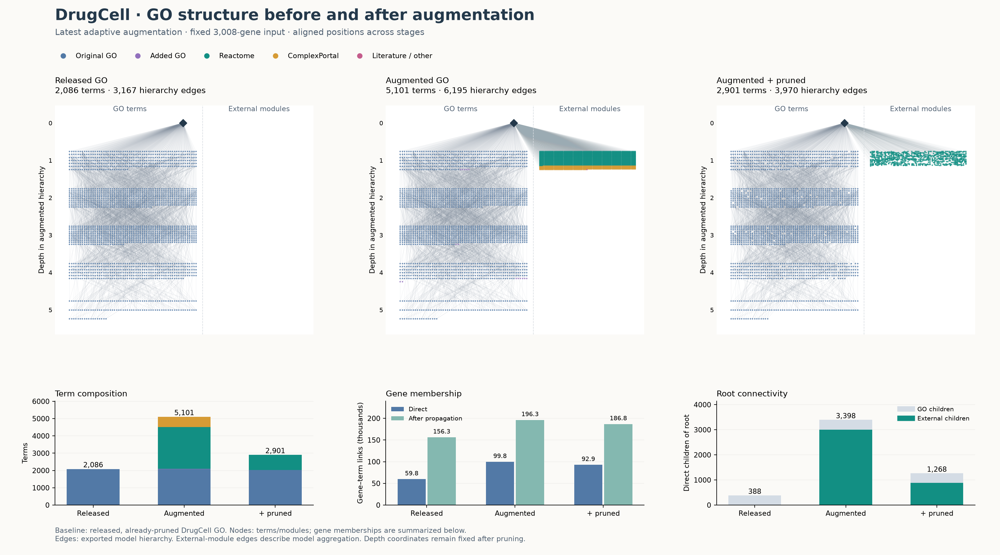

In [2]:
# Render an export for this notebook while preserving the earlier visualization files.
import sys
sys.path.insert(0, str(ROOT / "scripts"))
from visualize_drugcell_go import plot_overview

NOTEBOOK_EXPORTS = ROOT / "outputs/notebooks/02_drugcell_go_structure"
NOTEBOOK_EXPORTS.mkdir(parents=True, exist_ok=True)
plot_overview(data, NOTEBOOK_EXPORTS)
display(Image(filename=str(NOTEBOOK_EXPORTS / "overview.png"), width=1600))

## 3. Interactive comparison

- Search **TP53**, **DNA repair**, a **GO ID**, or a Reactome identifier.
- Click a node to compare its memberships across the three stages.
- Select its neighborhood, ancestors or descendants to inspect local structure.
- A gene search displays that gene's functional coverage and direct membership edges.
- Wheel to zoom and drag to pan; the three views move together.

The embedded viewer contains all its data and runs offline. The standalone viewer remains available beside the PNG/SVG/PDF exports.

In [3]:
viewer_source = (ARTIFACTS / "index.html").read_text()
# An isolated srcdoc iframe runs the viewer without relying on Jupyter's URL routing.
# The saved cell output includes the viewer and its graph data.
iframe = (
    '<iframe title="DrugCell GO structure comparison" '
    'sandbox="allow-scripts allow-downloads" '
    'style="width:100%;height:1250px;border:1px solid #dce3e9;border-radius:10px" '
    'srcdoc="' + html.escape(viewer_source, quote=True) + '"></iframe>'
)
display(HTML(iframe))
print("Standalone viewer:", ARTIFACTS / "index.html")

/home/yxcheng/project/GO_enrichment/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Standalone viewer: /home/yxcheng/project/GO_enrichment/outputs/analysis/drugcell_go_structure_005_001/index.html


## 4. Counts and module origins

**Direct** links are the memberships encoded in the exported model. **Propagated** links include membership inherited by ancestor modules. External attachment edges retain their recorded model-aggregation semantics.

In [4]:
summary_rows = []
for stage in data["stages"]:
    stats = stage["stats"]
    summary_rows.append({
        "stage": stage["title"],
        "terms": stats["terms"],
        "hierarchy edges": stats["hierarchy_edges"],
        "direct gene links": stats["direct_memberships"],
        "propagated gene links": stats["propagated_memberships"],
        "covered genes": stats["annotated_genes"],
        "root children": stage["root_children"],
        "external root children": stage["external_root_children"],
    })
display(pd.DataFrame(summary_rows).set_index("stage"))

origins = pd.DataFrame({stage["title"]: stage["source_counts"] for stage in data["stages"]}).fillna(0).astype(int)
display(origins.reindex(data["colors"], fill_value=0))

,terms,hierarchy edges,direct gene links,propagated gene links,covered genes,root children,external root children
stage,,,,,,,
Released GO,2086,3167,59753,156257,3008,388,0
Augmented GO,5101,6195,99767,196302,3008,3398,3000
Augmented + pruned,2901,3970,92855,186808,3008,1268,880


,Released GO,Augmented GO,Augmented + pruned
Original GO,2086,2086,2021
Added GO,0,15,0
Reactome,0,2403,880
ComplexPortal,0,596,0
Literature / other,0,1,0


## 5. Follow one input gene

Change `GENE` in the setup cell to compare its direct and propagated term memberships. The detailed table includes every term with a direct link to this gene in at least one stage.

In [5]:
def inspect_gene(gene):
    index = gene_indices[gene.upper()]
    counts, direct_union = [], set()
    for stage in data["stages"]:
        direct = {node["id"] for node in stage["nodes"] if index in node["direct"]}
        propagated = {node["id"] for node in stage["nodes"] if index in node["coverage"]}
        direct_union.update(direct)
        counts.append({"stage": stage["title"], "direct terms": len(direct), "propagated terms": len(propagated)})
    rows = []
    for identifier in sorted(direct_union):
        node = node_maps["augmented"][identifier]
        row = {"term": identifier, "name": node["label"], "origin": node["source"]}
        for key, stage in stages.items():
            current = node_maps[key].get(identifier)
            row[stage["title"]] = "direct" if current and index in current["direct"] else (
                "inherited" if current and index in current["coverage"] else "absent")
        rows.append(row)
    display(Markdown(f"### {gene.upper()}"))
    display(pd.DataFrame(counts).set_index("stage"))
    return pd.DataFrame(rows)


gene_memberships = inspect_gene(GENE)
with pd.option_context("display.max_rows", 120, "display.max_colwidth", 65):
    display(gene_memberships)

### TP53

,direct terms,propagated terms
stage,,
Released GO,127,312
Augmented GO,247,432
Augmented + pruned,221,400


,term,name,origin,Released GO,Augmented GO,Augmented + pruned
0,EXTERNAL:ComplexPortal:CPX-663,TP53-MDM4 transcription regulation complex,ComplexPortal,absent,direct,absent
1,EXTERNAL:ComplexPortal:CPX-759,TP53-MDM2 transcription regulation complex,ComplexPortal,absent,direct,absent
2,EXTERNAL:R-HSA-109581,Apoptosis,Reactome,absent,direct,direct
3,EXTERNAL:R-HSA-109606,Intrinsic Pathway for Apoptosis,Reactome,absent,direct,direct
4,EXTERNAL:R-HSA-111448,Activation of NOXA and translocation to mitochondria,Reactome,absent,direct,absent
...,...,...,...,...,...,...
243,GO:2000142,regulation of DNA-templated transcription initiation,Original GO,direct,direct,direct
244,GO:2000279,negative regulation of DNA biosynthetic process,Original GO,direct,direct,direct
245,GO:2000379,positive regulation of reactive oxygen species metabolic process,Original GO,direct,direct,direct
246,GO:2000772,regulation of cellular senescence,Original GO,direct,direct,direct


## 6. Zoom into one functional module

Change `TERM` in the setup cell to a GO ID or an exported external module ID. This figure shows the selected term and its immediate parents and children. It uses a shared local layout across stages; the overview above preserves the full-graph depth layout.

### DNA repair · GO:0006281

,present,direct genes,propagated genes,parents,children
stage,,,,,
Released GO,True,46,99,2,5
Augmented GO,True,46,99,2,5
Augmented + pruned,True,46,99,2,5


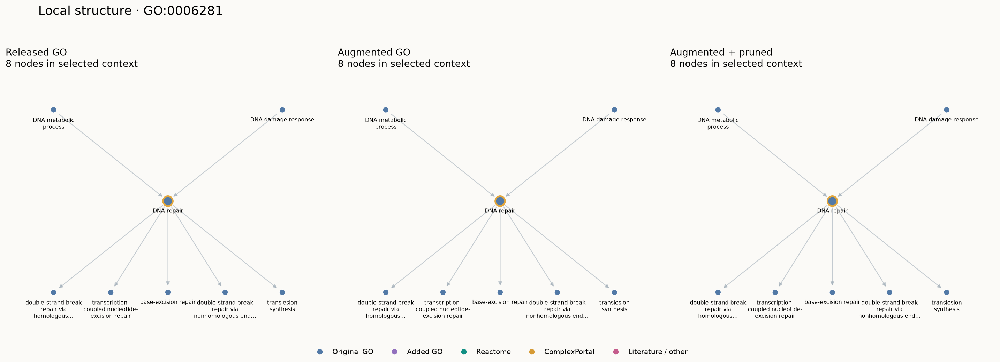

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
from textwrap import shorten, fill


@lru_cache(None)
def hierarchy(key):
    graph = nx.DiGraph()
    graph.add_nodes_from(node_maps[key])
    for parent, child, semantics in stages[key]["edges"]:
        graph.add_edge(stages[key]["nodes"][parent]["id"], stages[key]["nodes"][child]["id"], semantics=semantics)
    return graph


def inspect_term(identifier):
    matches = [node for node in stages["augmented"]["nodes"]
               if node["id"] == identifier or node["original_id"] == identifier]
    if not matches:
        raise KeyError(f"Term absent from the exported augmented graph: {identifier}")
    identifier = matches[0]["id"]
    rows = []
    selected = {identifier}
    for key, stage in stages.items():
        graph = hierarchy(key)
        node = node_maps[key].get(identifier)
        if node:
            selected.update(graph.predecessors(identifier))
            selected.update(graph.successors(identifier))
        rows.append({
            "stage": stage["title"], "present": node is not None,
            "direct genes": len(node["direct"]) if node else None,
            "propagated genes": len(node["coverage"]) if node else None,
            "parents": graph.in_degree(identifier) if node else None,
            "children": graph.out_degree(identifier) if node else None,
        })
    display(Markdown(f"### {matches[0]['label']} · {identifier}"))
    display(pd.DataFrame(rows).set_index("stage"))
    union = nx.DiGraph()
    for key in stages:
        union.update(hierarchy(key).subgraph(selected))
    # Fixed node ordering makes the local layout repeatable.
    ordered = nx.DiGraph()
    ordered.add_nodes_from(sorted(union.nodes))
    ordered.add_edges_from(sorted(union.edges))
    # Put parents above the selected module and children below it.
    # The same coordinates are reused in all three panels.
    layers = {-1: [], 0: [identifier], 1: []}
    for other in sorted(set(ordered) - {identifier}):
        layers[-1 if nx.has_path(ordered, other, identifier) else 1].append(other)
    positions = {}
    for layer, members in layers.items():
        for i, member in enumerate(members):
            x = 0.0 if len(members) == 1 else -1.0 + 2.0 * i / (len(members) - 1)
            positions[member] = np.array([x, -float(layer)])
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), facecolor="#fbfaf7")
    for ax, (key, stage) in zip(axes, stages.items()):
        local = hierarchy(key).subgraph(selected)
        nodes = list(local.nodes)
        colors = [data["colors"][node_maps[key][n]["source"]] for n in nodes]
        nx.draw_networkx_edges(local, positions, ax=ax, edge_color="#9eabb6", alpha=.6, arrows=True, arrowsize=10)
        nx.draw_networkx_nodes(local, positions, ax=ax, nodelist=nodes, node_color=colors,
                               node_size=[160 if n == identifier else 55 for n in nodes],
                               edgecolors=["#e2a63b" if n == identifier else "white" for n in nodes],
                               linewidths=[2 if n == identifier else .5 for n in nodes])
        labels = {n: fill(shorten(node_maps[key][n]["label"], width=52, placeholder="…"), width=20) for n in nodes}
        label_positions = {n: positions[n] + np.array([0.0, -.08]) for n in nodes}
        nx.draw_networkx_labels(local, label_positions, labels, ax=ax, font_size=7.2,
                                verticalalignment="top", clip_on=False)
        if identifier not in local:
            ax.text(.5, .05, "Selected module absent", transform=ax.transAxes, ha="center", color="#687789")
        ax.set_title(f"{stage['title']}\n{len(local):,} nodes in selected context", loc="left", fontsize=12)
        ax.set_axis_off()
    xy = np.array(list(positions.values()))
    pad = .42
    for ax in axes:
        ax.set_xlim(xy[:, 0].min() - pad, xy[:, 0].max() + pad)
        ax.set_ylim(xy[:, 1].min() - pad, xy[:, 1].max() + pad)
    fig.suptitle(f"Local structure · {identifier}", x=.04, ha="left", fontsize=16)
    fig.legend(handles=[Line2D([], [], marker="o", lw=0, color=color, label=source)
                        for source, color in data["colors"].items()], loc="lower center", ncol=5, frameon=False)
    fig.tight_layout(rect=(0, .06, 1, .94))
    local_png = NOTEBOOK_EXPORTS / "local_structure.png"
    fig.savefig(local_png, dpi=160, bbox_inches="tight", facecolor=fig.get_facecolor())
    display(Image(filename=str(local_png), width=1600))
    plt.close(fig)
    return identifier


selected_term = inspect_term(TERM)

## 7. Exported artifacts

The graph tables and original figures remain alongside the standalone viewer. `manifest.json` records source checksums. The graph comparison uses the released DrugCell GO as its baseline.

In [7]:
for name in ["index.html", "overview.png", "overview.svg", "overview.pdf", "nodes.tsv", "edges.tsv", "manifest.json"]:
    path = ARTIFACTS / name
    print(f"{path.relative_to(ROOT)}  ({path.stat().st_size / 1024**2:.2f} MiB)")
print("Notebook figure exports:", NOTEBOOK_EXPORTS)

outputs/analysis/drugcell_go_structure_005_001/index.html  (7.86 MiB)
outputs/analysis/drugcell_go_structure_005_001/overview.png  (2.23 MiB)
outputs/analysis/drugcell_go_structure_005_001/overview.svg  (3.31 MiB)
outputs/analysis/drugcell_go_structure_005_001/overview.pdf  (0.14 MiB)
outputs/analysis/drugcell_go_structure_005_001/nodes.tsv  (1.20 MiB)
outputs/analysis/drugcell_go_structure_005_001/edges.tsv  (0.72 MiB)
outputs/analysis/drugcell_go_structure_005_001/manifest.json  (0.00 MiB)
Notebook figure exports: /home/yxcheng/project/GO_enrichment/outputs/notebooks/02_drugcell_go_structure
